<a href="https://colab.research.google.com/github/Turbonik/Data-Analysis/blob/main/MAD_3_ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = [12, 6]

df = pd.read_csv('Groceries_dataset.csv')

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
print("\nТипы данных:")
print(df.dtypes)
print("\nПропуски:")
print(df.isnull().sum())

print(f"Уникальных товаров (кардинальность): {df['itemDescription'].nunique()}")
print("\nТоп-10 самых частых товаров:")
print(df['itemDescription'].value_counts().head(10))

plt.figure(figsize=(12, 6))
top_items = df['itemDescription'].value_counts().head(15)
sns.barplot(x=top_items.values, y=top_items.index, palette='viridis')
plt.title('Частота встречаемости (Топ-15 товаров)')
plt.xlabel('Количество записей')
plt.ylabel('Товар')
plt.tight_layout()
plt.show()

# дата
df['Date'] = pd.to_datetime(df['Date'], dayfirst=True)
print(f"Минимальная дата: {df['Date'].min().date()}")
print(f"Максимальная дата: {df['Date'].max().date()}")
print(f"Количество уникальных дат (дней с покупками): {df['Date'].nunique()}")

df['YearMonth'] = df['Date'].dt.to_period('M').astype(str)
monthly_counts = df['YearMonth'].value_counts().sort_index()

plt.figure(figsize=(14, 5))
sns.barplot(x=monthly_counts.index, y=monthly_counts.values, palette='Blues_d')
plt.title('Гистограмма: Количество покупок по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество покупок')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# id
print(f"Уникальных покупателей: {df['Member_number'].nunique()}")
print(f"Мин. ID: {df['Member_number'].min()}, Макс. ID: {df['Member_number'].max()}")

purchases_per_user = df['Member_number'].value_counts()

plt.figure(figsize=(10, 5))
sns.histplot(purchases_per_user, bins=30, kde=False, color='orange')
plt.title('Гистограмма: Сколько покупок совершил каждый покупатель (за 2 года)')
plt.xlabel('Количество записей о покупках')
plt.ylabel('Количество покупателей')
plt.tight_layout()
plt.show()

print("\nСтатистика по количеству покупок на человека (на основе группировки):")
print(purchases_per_user.describe().round(2))

FileNotFoundError: [Errno 2] No such file or directory: 'data/Groceries_dataset.csv'

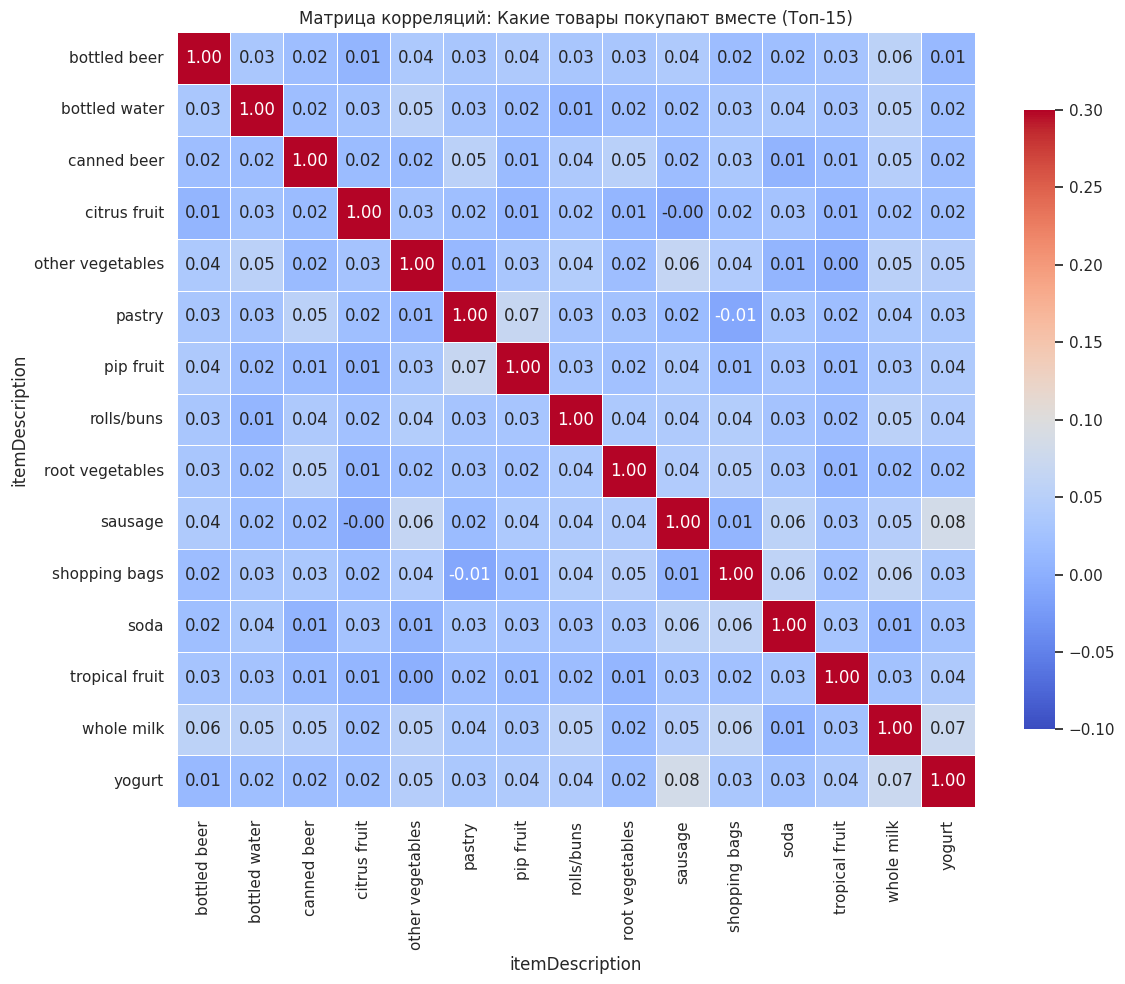


 Самые сильноположительные связи
          Item_1     Item_2  Correlation
         sausage     yogurt     0.083051
      whole milk     yogurt     0.073331
          pastry  pip fruit     0.067489
other vegetables    sausage     0.064192
   shopping bags whole milk     0.061986


In [ ]:
top_15_items = df['itemDescription'].value_counts().head(15).index.tolist()

df_top_items = df[df['itemDescription'].isin(top_15_items)]
pivot_df = pd.crosstab(df_top_items['Member_number'], df_top_items['itemDescription'])
pivot_df = (pivot_df > 0).astype(int)

corr_matrix = pivot_df.corr()
plt.figure(figsize=(12, 10))

sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    vmax=0.3, vmin=-0.1,
    annot=True,
    fmt=".2f",
    linewidths=.5,
    cbar_kws={"shrink": .8}
)
plt.title('Матрица корреляций: Какие товары покупают вместе (Топ-15)')
plt.tight_layout()
plt.show()

print("\n Самые сильноположительные связи")

corr_series = corr_matrix.unstack()
corr_series.index.names = ['Item_1', 'Item_2']
corr_df = corr_series.reset_index(name='Correlation')

corr_df = corr_df[corr_df['Item_1'] < corr_df['Item_2']]

corr_df = corr_df.sort_values(by='Correlation', ascending=False)

print(corr_df.head(5).to_string(index=False))

Расчет метрик для разных k (K-Modes). Это может занять 1-2 минуты...
k=2: Cost=32980.00, Silhouette=0.0781 (время: 8.9с)
k=3: Cost=33002.00, Silhouette=0.0830 (время: 7.6с)
k=4: Cost=31903.00, Silhouette=0.0121 (время: 13.4с)
k=5: Cost=31966.00, Silhouette=0.0274 (время: 11.9с)
k=6: Cost=31108.00, Silhouette=0.0337 (время: 14.3с)
k=7: Cost=31015.00, Silhouette=0.0400 (время: 15.0с)
k=8: Cost=30912.00, Silhouette=-0.0251 (время: 15.5с)


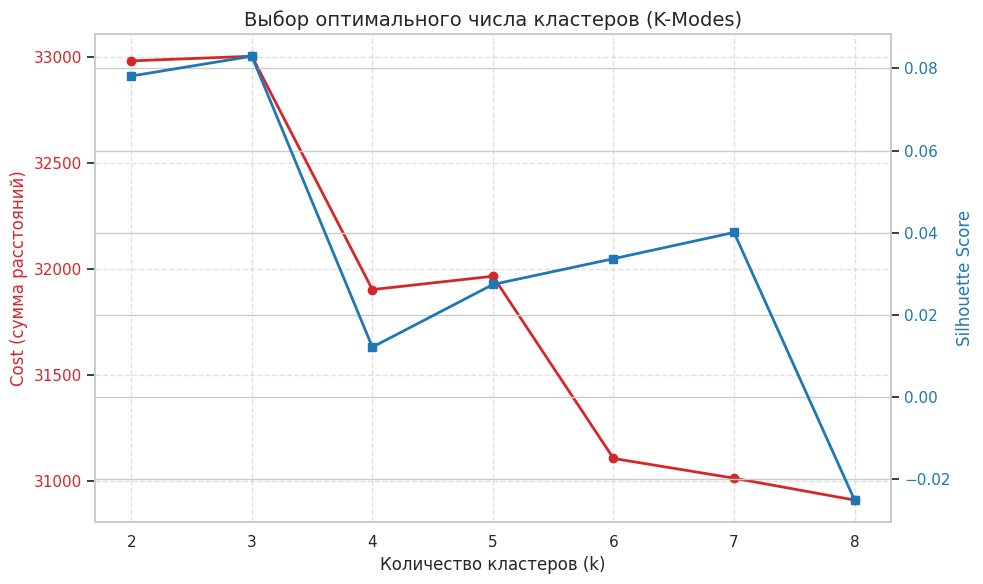


Лучшее k по методу силуэта: 3
Максимальный Silhouette Score: 0.0830


In [ ]:
!pip install kmodes -q

from kmodes.kmodes import KModes
from sklearn.metrics import silhouette_score
import time

print("Расчет метрик для разных k (K-Modes). Это может занять 1-2 минуты...")

costs = []
silhouettes = []
K_range = range(2, 10)
for k in K_range:
    start_time = time.time()
    km = KModes(n_clusters=k, init='Huang', n_init=2, verbose=0, random_state=42)
    clusters = km.fit_predict(items_matrix)

    costs.append(km.cost_)

    if len(set(clusters)) > 1:
        sil = silhouette_score(items_matrix, clusters, metric='hamming')
    else:
        sil = 0
    silhouettes.append(sil)

    print(f"k={k}: Cost={km.cost_:.2f}, Silhouette={sil:.4f} (время: {time.time()-start_time:.1f}с)")

fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.set_xlabel('Количество кластеров (k)', fontsize=12)
ax1.set_ylabel('Cost (сумма расстояний)', color='tab:red', fontsize=12)
ax1.plot(K_range, costs, marker='o', color='tab:red', linewidth=2, label='Cost')
ax1.tick_params(axis='y', labelcolor='tab:red')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2 = ax1.twinx()
ax2.set_ylabel('Silhouette Score', color='tab:blue', fontsize=12)
ax2.plot(K_range, silhouettes, marker='s', color='tab:blue', linewidth=2, label='Silhouette')
ax2.tick_params(axis='y', labelcolor='tab:blue')

plt.title('Выбор оптимального числа кластеров (K-Modes)', fontsize=14)
fig.tight_layout()
plt.show()

best_k = K_range[silhouettes.index(max(silhouettes))]
print(f"\nЛучшее k по методу силуэта: {best_k}")
print(f"Максимальный Silhouette Score: {max(silhouettes):.4f}")

In [ ]:
from kmodes.util.dissim import matching_dissim

n_clusters = 4

km = KModes(n_clusters=n_clusters, init='Huang', n_init=5, verbose=0, random_state=42)
clusters = km.fit_predict(items_matrix)

df_grouped['Cluster'] = clusters

# центры
centroids = km.cluster_centroids_
print(f"центры кластеров (Модальные товары, k={n_clusters})")
print("\n")

for i in range(n_clusters):
    centroid = centroids[i]
    top_indices = np.argsort(centroid)[-5:][::-1]
    top_items = [mlb.classes_[idx] for idx in top_indices]
    size = sum(clusters == i)
    print(f"Кластер {i} (Размер: {size} чел.): {', '.join(top_items)}")

# расстояние до центров
distances = []
for i in range(len(items_matrix)):
    cluster_id = clusters[i]
    center = centroids[cluster_id]
    dist = matching_dissim(items_matrix[i].reshape(1, -1), center.reshape(1, -1))[0]
    distances.append(dist)

df_grouped['Distance_to_Center'] = distances

print("\n среднее расстояние до центров по кластерам")
dist_stats = df_grouped.groupby('Cluster')['Distance_to_Center'].agg(['mean', 'min', 'max', 'std']).round(2)
print(dist_stats)

# внутренние
print("\n внутренние метрики качества")

sil_score = silhouette_score(items_matrix, clusters, metric='hamming')
print(f"\n Silhouette Score (мера Хэмминга): {sil_score:.4f}")
print(f"Cost (целевая функция): {km.cost_:.2f}")

# Средняя плотность (сколько несовпадений в среднем)
avg_dist = df_grouped['Distance_to_Center'].mean()
print(f"\n Среднее расстояние до центра: {avg_dist:.2f} (из {items_matrix.shape[1]} возможных)")

центры кластеров (Модальные товары, k=4)


Кластер 0 (Размер: 1165 чел.): soda, other vegetables, yogurt, white wine, white bread
Кластер 1 (Размер: 511 чел.): canned beer, yogurt, zwieback, white wine, white bread
Кластер 2 (Размер: 992 чел.): whole milk, other vegetables, rolls/buns, white wine, white bread
Кластер 3 (Размер: 1230 чел.): zwieback, yogurt, whole milk, white wine, white bread

 среднее расстояние до центров по кластерам
         mean  min  max   std
Cluster                      
0        8.47    1   22  4.01
1        9.47    0   21  4.00
2        9.47    0   23  3.97
3        6.34    1   21  3.35

 внутренние метрики качества

 Silhouette Score (мера Хэмминга): 0.0121
Cost (целевая функция): 31903.00

 Среднее расстояние до центра: 8.18 (из 167 возможных)


In [ ]:
from scipy.stats import kruskal

# значимость через краскела
significant_items = []

for i, item_name in enumerate(mlb.classes_):
    item_vector = items_matrix[:, i]

    groups = [item_vector[clusters == c] for c in range(n_clusters)]

    if all(len(g) == 0 for g in groups):
        continue

    try:
        stat, p_val = kruskal(*groups)

        if p_val < 0.05:
            means = [np.mean(g) for g in groups]
            max_diff = max(means) - min(means)

            significant_items.append({
                'Item': item_name,
                'P-value': p_val,
                'Max_Diff': max_diff
            })
    except ValueError:
        pass

df_sig = pd.DataFrame(significant_items).sort_values(by='Max_Diff', ascending=False)

print(f"\nВсего значимых товаров (p < 0.05): {len(df_sig)} из {len(mlb.classes_)}")
print("\n10 товаров, сильнее всего разделяющих кластеры:")
print(df_sig.head(10).to_string(index=False))


Всего значимых товаров (p < 0.05): 53 из 167

10 товаров, сильнее всего разделяющих кластеры:
            Item       P-value  Max_Diff
     canned beer  0.000000e+00  1.000000
            soda  0.000000e+00  0.749356
other vegetables 1.644219e-295  0.692540
      whole milk 7.947896e-208  0.606999
      rolls/buns 1.060977e-227  0.598148
          yogurt  2.377337e-08  0.118091
         sausage  1.439562e-06  0.092471
 root vegetables  1.197430e-03  0.079664
          pastry  1.090984e-04  0.079190
   shopping bags  2.319069e-05  0.076572
